In [7]:
# Imports necesarios para el notebook

from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
import scipy as sp

from util import time_algorithm

sns.set_theme()


#1 Algortimo a testear
def resolver(monedas):

    izquierda = 0
    derecha = len(monedas) - 1

    decisiones = []
    ganancia_sophia = 0

    turno_sophia = True

    while izquierda <= derecha:

        if turno_sophia:
            # Sophia elige la mondea de mayor valor disponible.
            if monedas[izquierda] >= monedas[derecha]:
                ganancia_sophia += monedas[izquierda]
                decisiones.append("Primera moneda para Sophia")
                izquierda += 1
            else:
                ganancia_sophia += monedas[derecha]
                decisiones.append("Última moneda para Sophia")
                derecha -= 1

        else:
            # Sophia decide que moneda recibe Mateo.
            # Le asigna la de menor vlaor disponible.
            if monedas[izquierda] <= monedas[derecha]:
                decisiones.append("Primera moneda para Mateo")
                
                izquierda += 1
            else:
                decisiones.append("Última moneda para Mateo")
                derecha -= 1

        turno_sophia = not turno_sophia

    return decisiones, ganancia_sophia







In [8]:
# Experimento 1: monedas con valores entre 1 y 100
def monedas_chicas(n):
    return np.random.randint(1, 101, n)

# Experimento 2: monedas con valores entre 1.000.000 y 1.000.100
def monedas_grandes(n):
    return np.random.randint(1_000_000, 1_000_101, n)

# Experimento 3: valores concentrados alrededor de 500.000
def monedas_baja_variabilidad(n):
    return np.random.randint(499_995, 500_006, n)

# Experimento 4: valores distribuidos en un intervalo amplio
def monedas_alta_variabilidad(n):
    return np.random.randint(1, 1_000_001, n)

In [9]:
#Generamos 20 secuencias de monedas de distintos tamaños 
x = np.linspace(100, 500_000, 20).astype(int)


# Fijamos la semilla para poder reproducir los experimentos
np.random.seed(12345)


# Asociamos cada experimento con su generador
experimentos = {
    "Valores chicos": monedas_chicas,
    "Valores grandes": monedas_grandes,
    "Baja variabilidad": monedas_baja_variabilidad,
    "Alta variabilidad": monedas_alta_variabilidad
}

# Guardamos los tiempos medidos de cada experimento
resultados_experimentos = {}

for nombre, generador in experimentos.items():

    resultados = time_algorithm(
        resolver,
        x,
        lambda n: [generador(n)]
    )

    resultados_experimentos[nombre] = resultados


In [10]:
import pandas as pd

tabla_tiempos = pd.DataFrame({
    nombre: [
        resultados_experimentos[nombre][n]
        for n in x
    ]
    for nombre in experimentos
}, index=x)

tabla_tiempos.index.name = "Cantidad de monedas"

display(tabla_tiempos)

,Valores chicos,Valores grandes,Baja variabilidad,Alta variabilidad
Cantidad de monedas,,,,
100,0.000069,0.000066,0.000045,0.000137
26410,0.015443,0.009512,0.009846,0.016322
52721,0.014378,0.022720,0.015776,0.014728
79031,0.021098,0.025353,0.020341,0.021449
105342,0.029363,0.028443,0.027299,0.030796
131652,0.036274,0.034193,0.034025,0.036432
157963,0.041434,0.040601,0.044307,0.044687
184273,0.048398,0.047279,0.047753,0.056962
210584,0.054444,0.054442,0.053748,0.055442


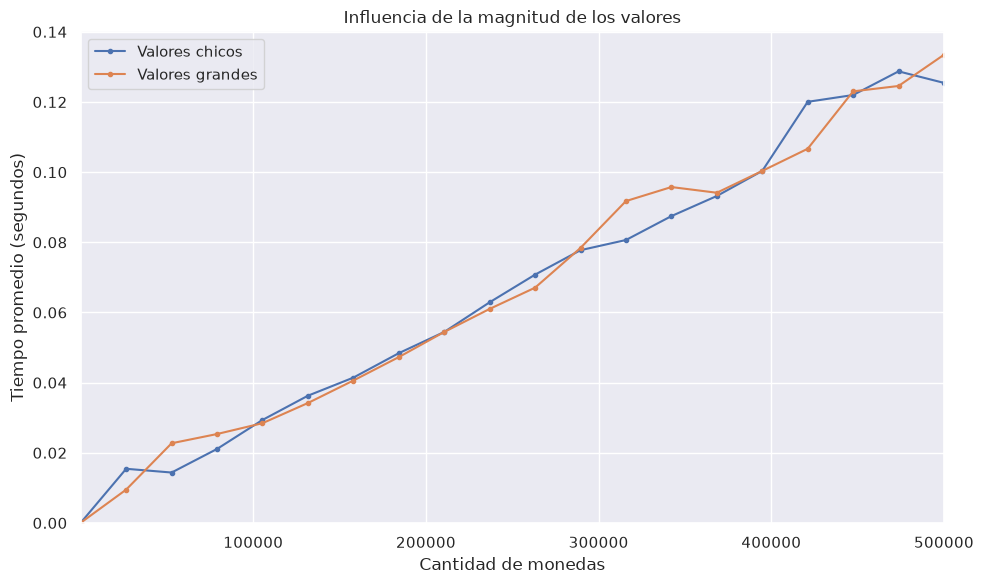

In [11]:
plt.figure(figsize=(10, 6))

plt.plot(
    x,
    tabla_tiempos["Valores chicos"],
    marker="o",
    markersize=3,
    label="Valores chicos"
)

plt.plot(
    x,
    tabla_tiempos["Valores grandes"],
    marker="o",
    markersize=3,
    label="Valores grandes"
)

plt.xlim(100, 500000)
plt.ylim(bottom=0)

plt.xlabel("Cantidad de monedas")
plt.ylabel("Tiempo promedio (segundos)")
plt.title("Influencia de la magnitud de los valores")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


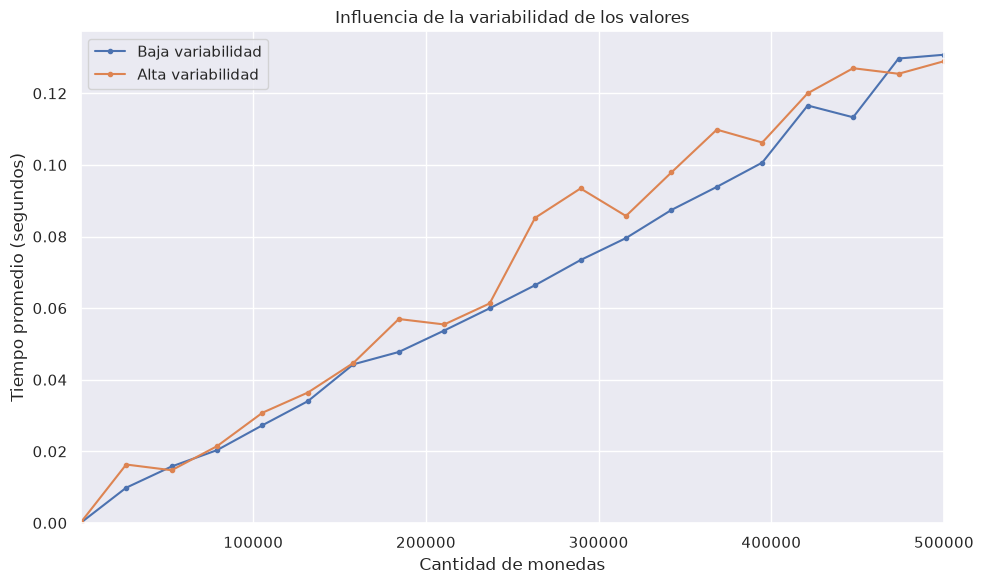

In [12]:

plt.figure(figsize=(10, 6))

plt.plot(
    x,
    tabla_tiempos["Baja variabilidad"],
    marker="o",
    markersize=3,
    label="Baja variabilidad"
)

plt.plot(
    x,
    tabla_tiempos["Alta variabilidad"],
    marker="o",
    markersize=3,
    label="Alta variabilidad"
)

plt.xlim(100, 500000)
plt.ylim(bottom=0)

plt.xlabel("Cantidad de monedas")
plt.ylabel("Tiempo promedio (segundos)")
plt.title("Influencia de la variabilidad de los valores")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
